# Cost against quality on SCAN-B, training on 70%

Selection time against test ROC AUC, one point per selector and k.
A point is on the frontier (blue) when no other point is both faster and better.

The data comes from three runs on the same splits:

- `configs/frontier_scanb70_gpu.yaml`: the selectors that run on the GPU.
- `configs/frontier_scanb70_seq.yaml`: Sequential selection on the GPU, one fit per selection.
- `configs/frontier_scanb70_cpu.yaml`: the selectors that run on the CPU.

Each run trains on 70% of the patients, over 5 splits, with logistic regression.
The first plot covers all five PAM50 tasks. Then each task has its own plot.
The CSVs are in `results/local/`, which git ignores; this notebook only plots them.

In [1]:
import contextlib
import io
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'scripts'))
import plot_frontier

LOCAL = ROOT / 'results' / 'local'
OUT = LOCAL / 'frontier_scanb70_roc_auc.png'
csvs = [LOCAL / f'frontier_scanb70_{run}.csv' for run in ('gpu', 'seq', 'cpu')]
with contextlib.redirect_stdout(io.StringIO()):   # its tables go to CSVs beside the plots
    plot_frontier.main([*map(str, csvs), '--out', str(OUT)])

## All tasks

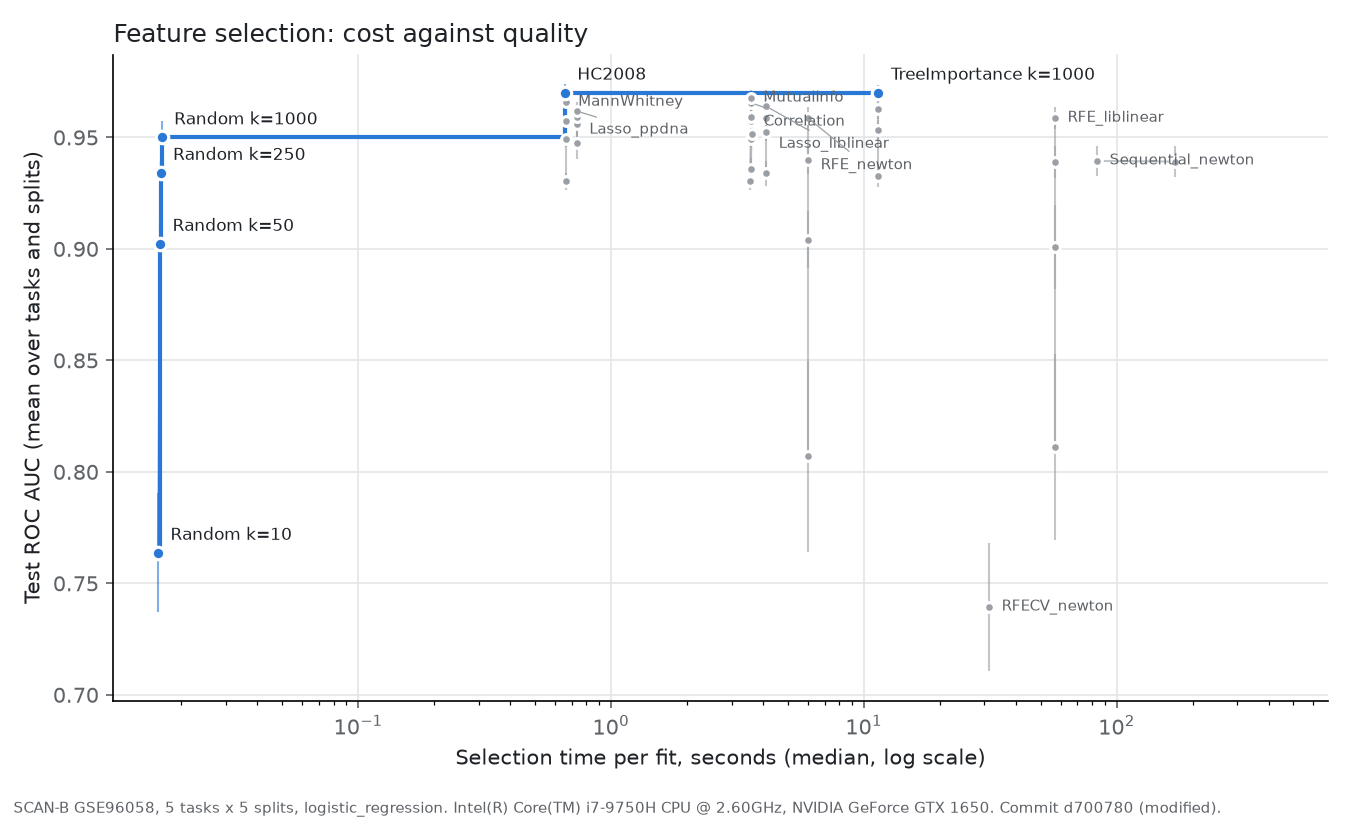

In [2]:
display(Image(filename=OUT))

## Each task

### Basal against the rest

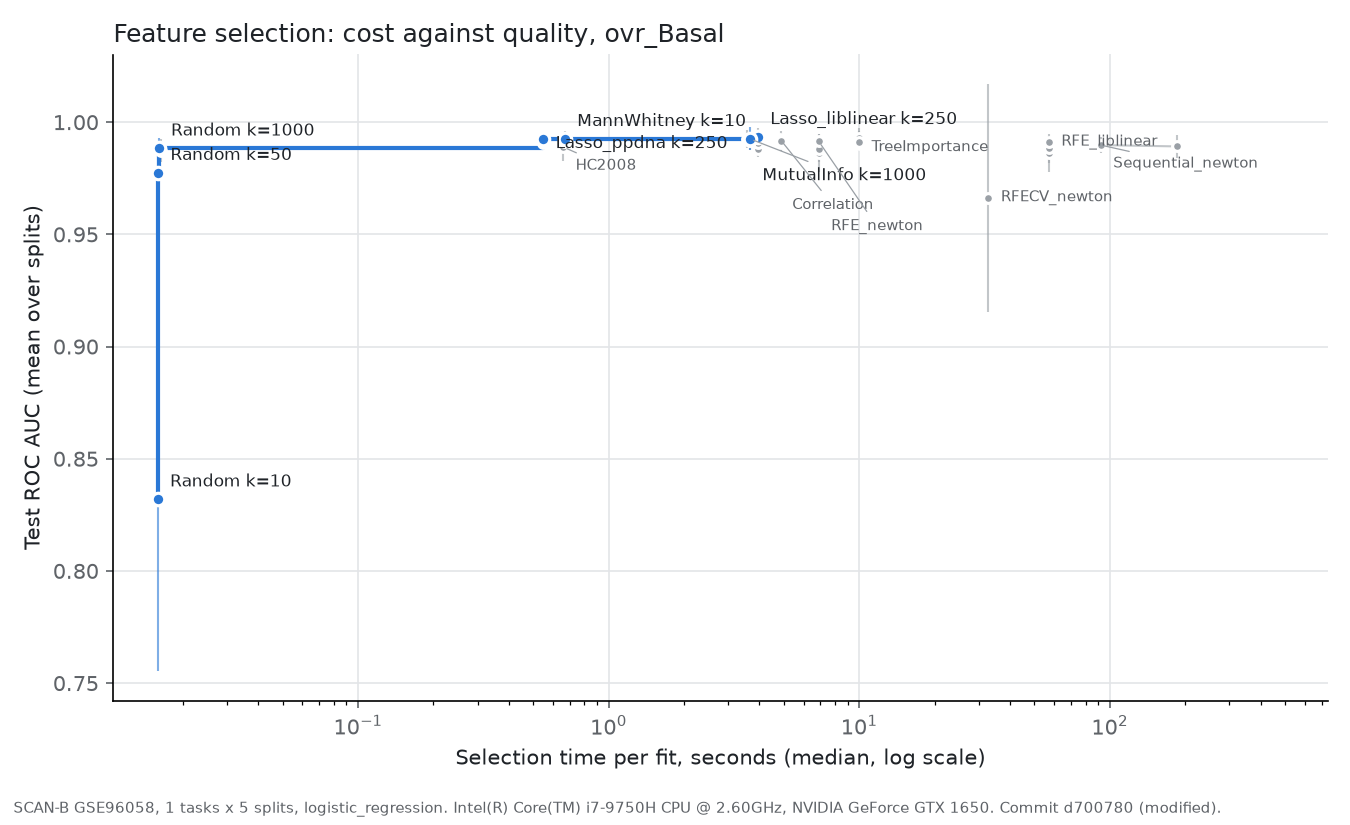

### Her2 against the rest

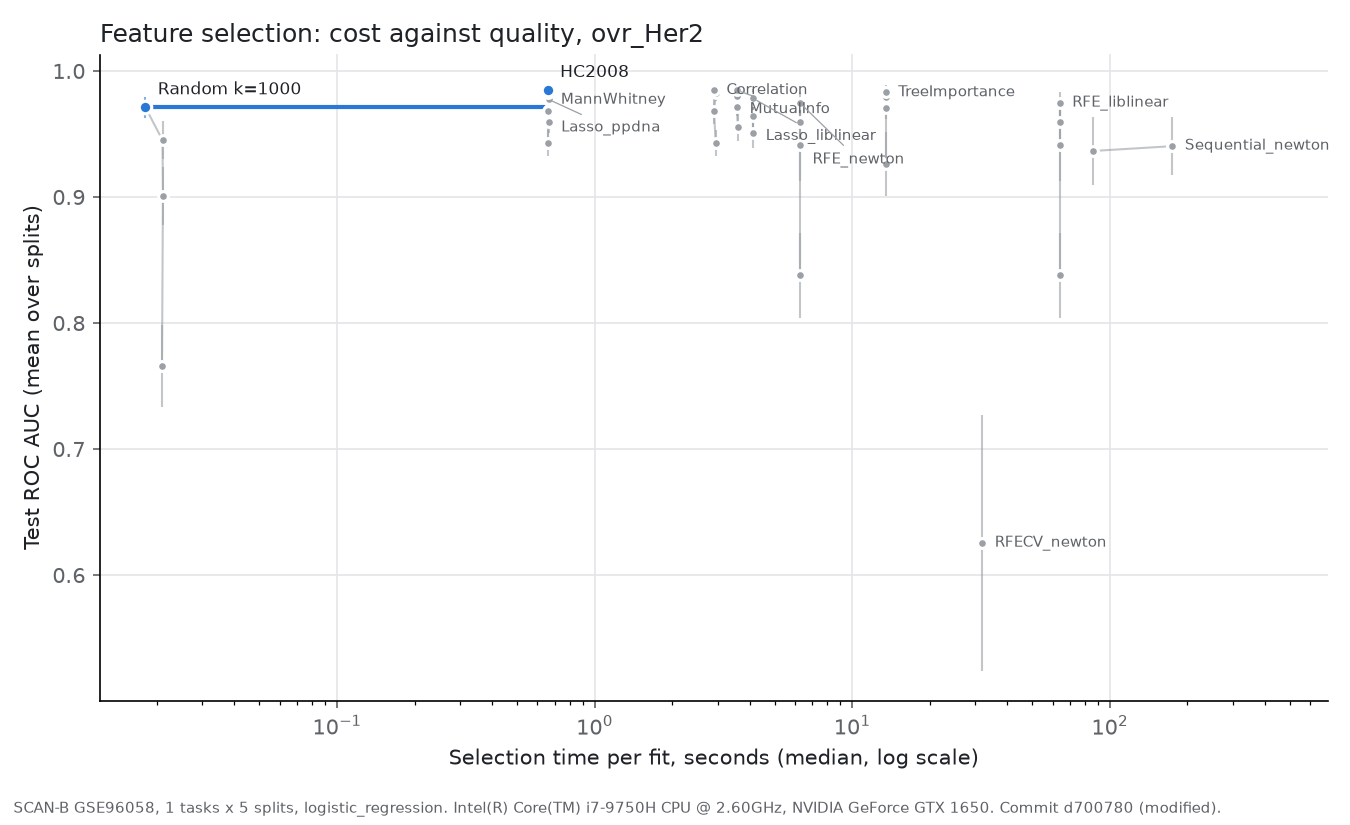

### LumA against the rest

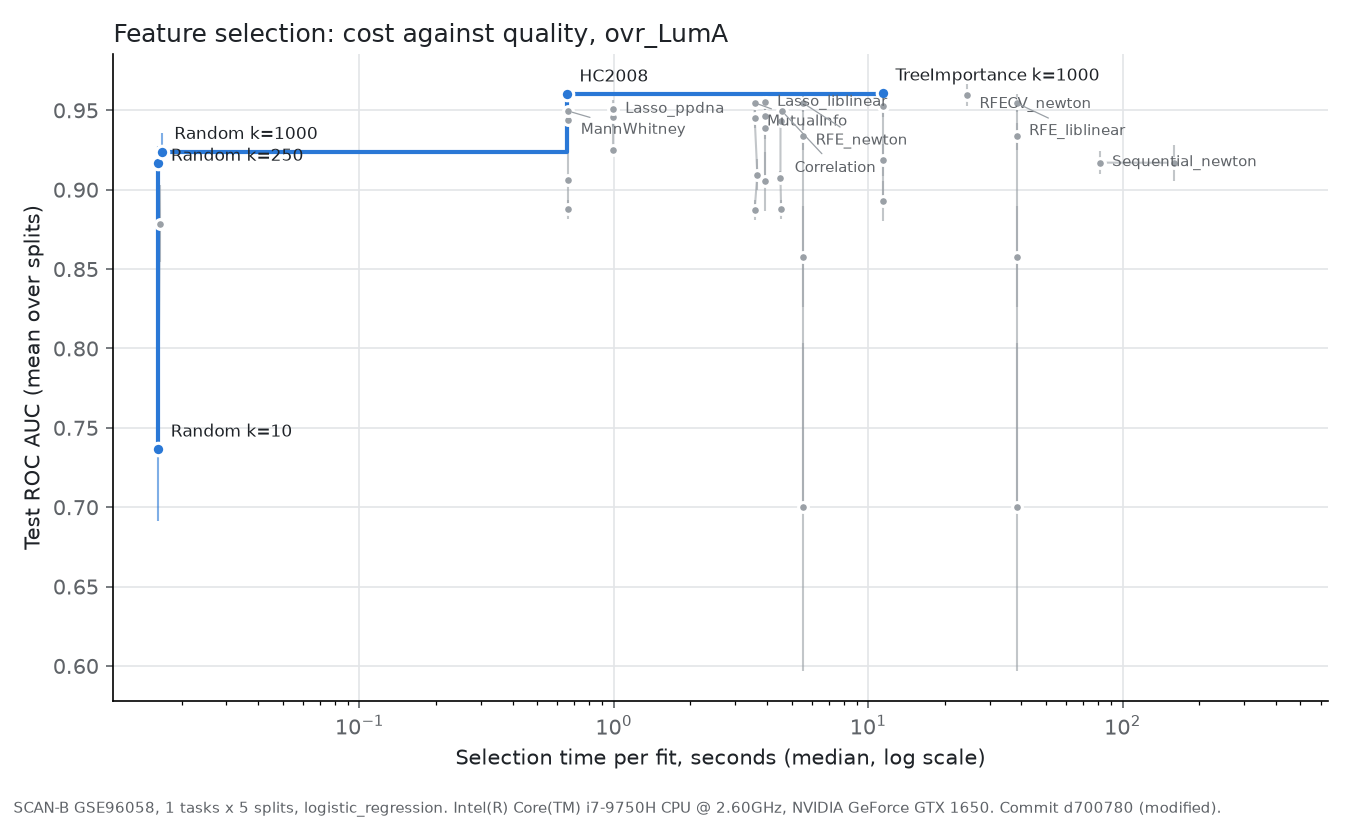

### LumB against the rest

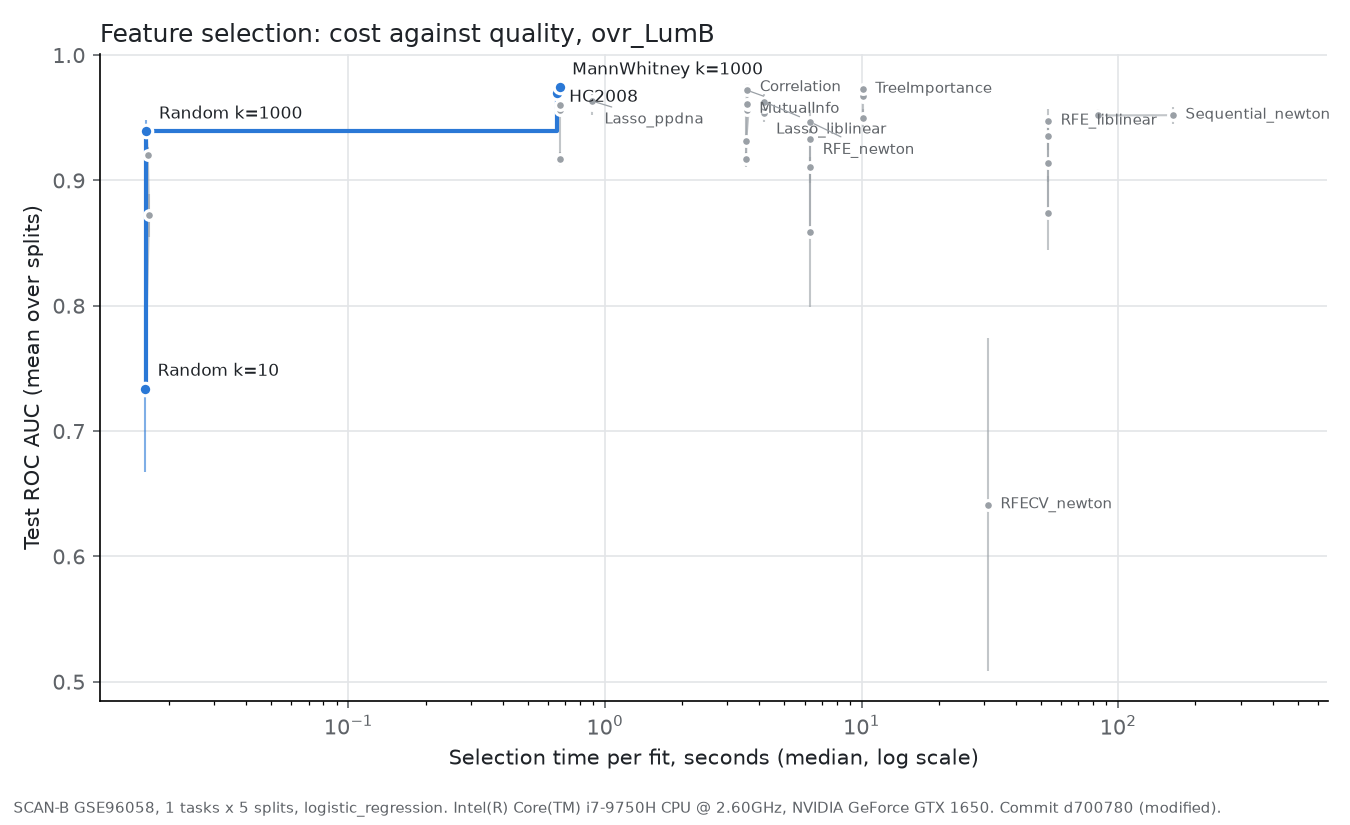

### Normal against the rest

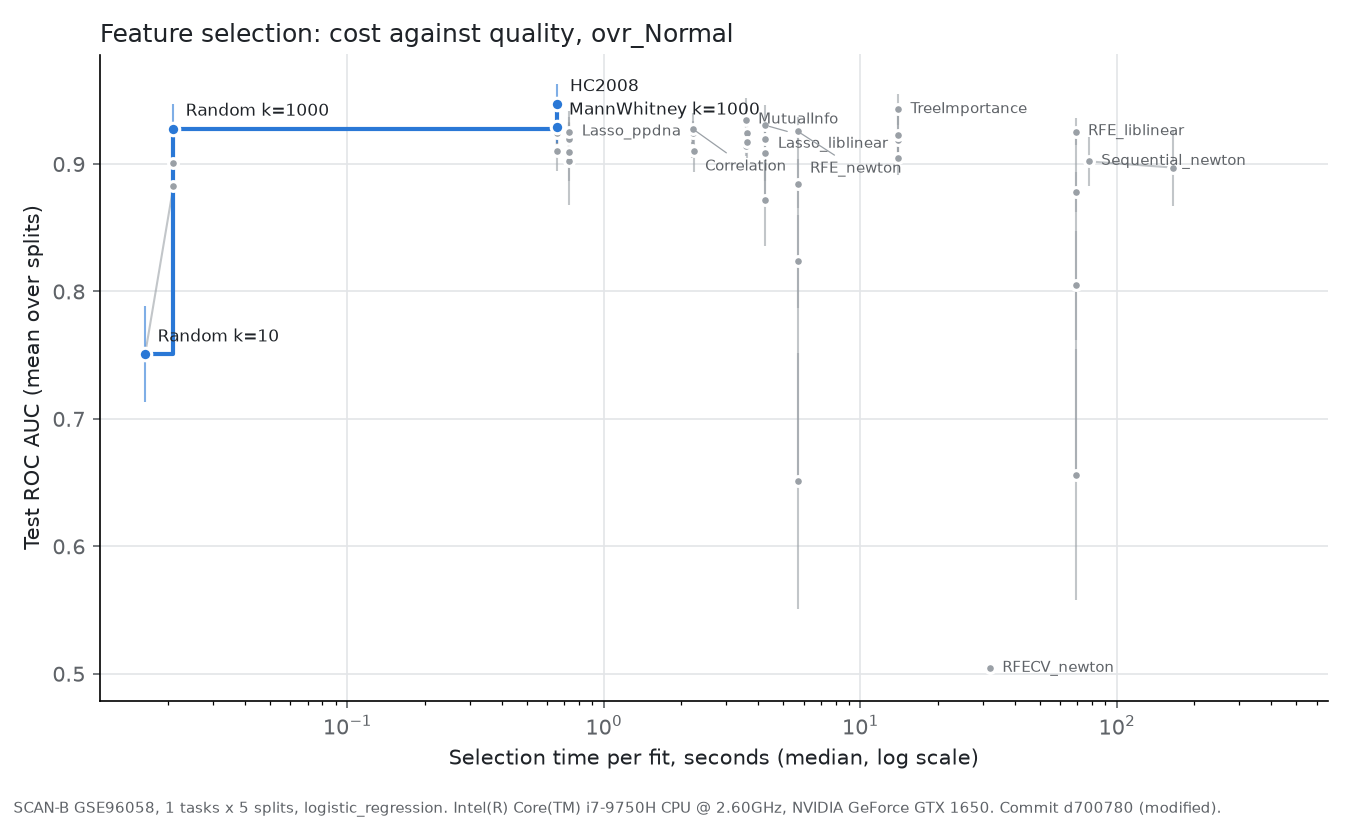

In [3]:
for task in ('Basal', 'Her2', 'LumA', 'LumB', 'Normal'):
    display(Markdown(f'### {task} against the rest'))
    display(Image(filename=OUT.with_name(f'{OUT.stem}_ovr_{task}.png')))